# Raw Temporal Research Recovery — Phase 0–4

Notebook chỉ đọc artifacts đã lưu, **không huấn luyện mô hình**. Các bảng bên dưới là số liệu thực nghiệm đã hoàn tất tại thời điểm chạy cell. Phase còn thiếu được ghi rõ; không thay số liệu chưa chạy bằng0.

Tất cả kết quả nội bộ mới là **thăm dò** do cohort đã được nghiên cứu nhiều lần. Development chỉ dùng143 Train/72 validation trong outer Train0;43 outer Test không dùng để chọn thiết kế. Kinematic baseline và v1 được bảo toàn.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'results').exists(): ROOT = ROOT.parent
OUT = ROOT / 'results/raw_temporal_v2'
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
def table(relative):
    path = OUT / relative
    if path.exists():
        frame = pd.read_csv(path)
        display(frame)
        return frame
    display(Markdown('**Chưa có artifact:** `' + relative + '`'))
def figure(name):
    path = OUT / 'figures' / (name + '.png')
    if path.exists(): display(Image(filename=str(path)))
    else: display(Markdown('Hình chưa được tạo: `' + name + '`'))
status = json.loads((OUT / 'validation.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'item': k, 'status': str(v)} for k, v in status.items()]))

,item,status
0,complete,False
1,phase0,complete
2,phase1,complete
3,phase2,in_progress
4,phase3,planned
5,phase4,planned
6,external_evaluation_status,not_yet_audited
7,unfinished,['Phases1ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Å“4 experimental exec...


## Phase 0 — Kiểm tra kỹ thuật
Tiny Train memorization kiểm tra khả năng tối ưu, không đo generalization. Synthetic là fixture ở mức representation, không phải mô phỏng SVC vật lý hoàn chỉnh.

In [2]:
tiny = table('tables/phase0_memorization.csv')
synthetic = table('tables/phase0_synthetic_results.csv')

,model,participants,epochs,eval_train_bce,macro_f1,embedding_variance,mean_pair_distance,train_seconds,gpu_peak_mib
0,cnn,16,52,0.014184,1.0,0.034523,1.380872,15.369684,911.361328
1,cnn,8,41,0.019326,1.0,0.006713,0.615001,6.890491,664.873535
2,hierarchical,16,89,0.015744,1.0,1.208247,7.797385,62.986368,911.403809
3,hierarchical,8,35,0.022947,1.0,0.719767,5.944748,12.117077,665.295410
4,tcn,16,48,0.017718,1.0,0.032691,1.305133,19.464781,911.132324
5,tcn,8,36,0.021274,1.0,0.035476,1.368518,7.654899,665.086914


,test,model,seed,f1_macro,accuracy,auc,stats_accuracy,epochs,best_epoch,parameters,train_seconds
0,event_order,cnn,42,1.0,1.0,1.0,0.5,40,40,2610,4.898514
1,event_order,cnn,43,1.0,1.0,1.0,0.5,30,30,2610,3.814058
2,event_order,hierarchical,42,1.0,1.0,1.0,0.5,30,30,11154,5.545887
3,event_order,hierarchical,43,1.0,1.0,1.0,0.5,30,30,11154,5.699852
4,event_order,tcn,42,1.0,1.0,1.0,0.5,47,47,11986,9.643034
5,event_order,tcn,43,1.0,1.0,1.0,0.5,30,30,11986,6.086580
6,physical_time,cnn,42,1.0,1.0,1.0,1.0,30,30,2610,3.268608
7,physical_time,cnn,43,1.0,1.0,1.0,1.0,30,30,2610,3.269332
8,physical_time,hierarchical,42,1.0,1.0,1.0,1.0,30,30,11154,4.385794
9,physical_time,hierarchical,43,1.0,1.0,1.0,1.0,30,30,11154,4.267037


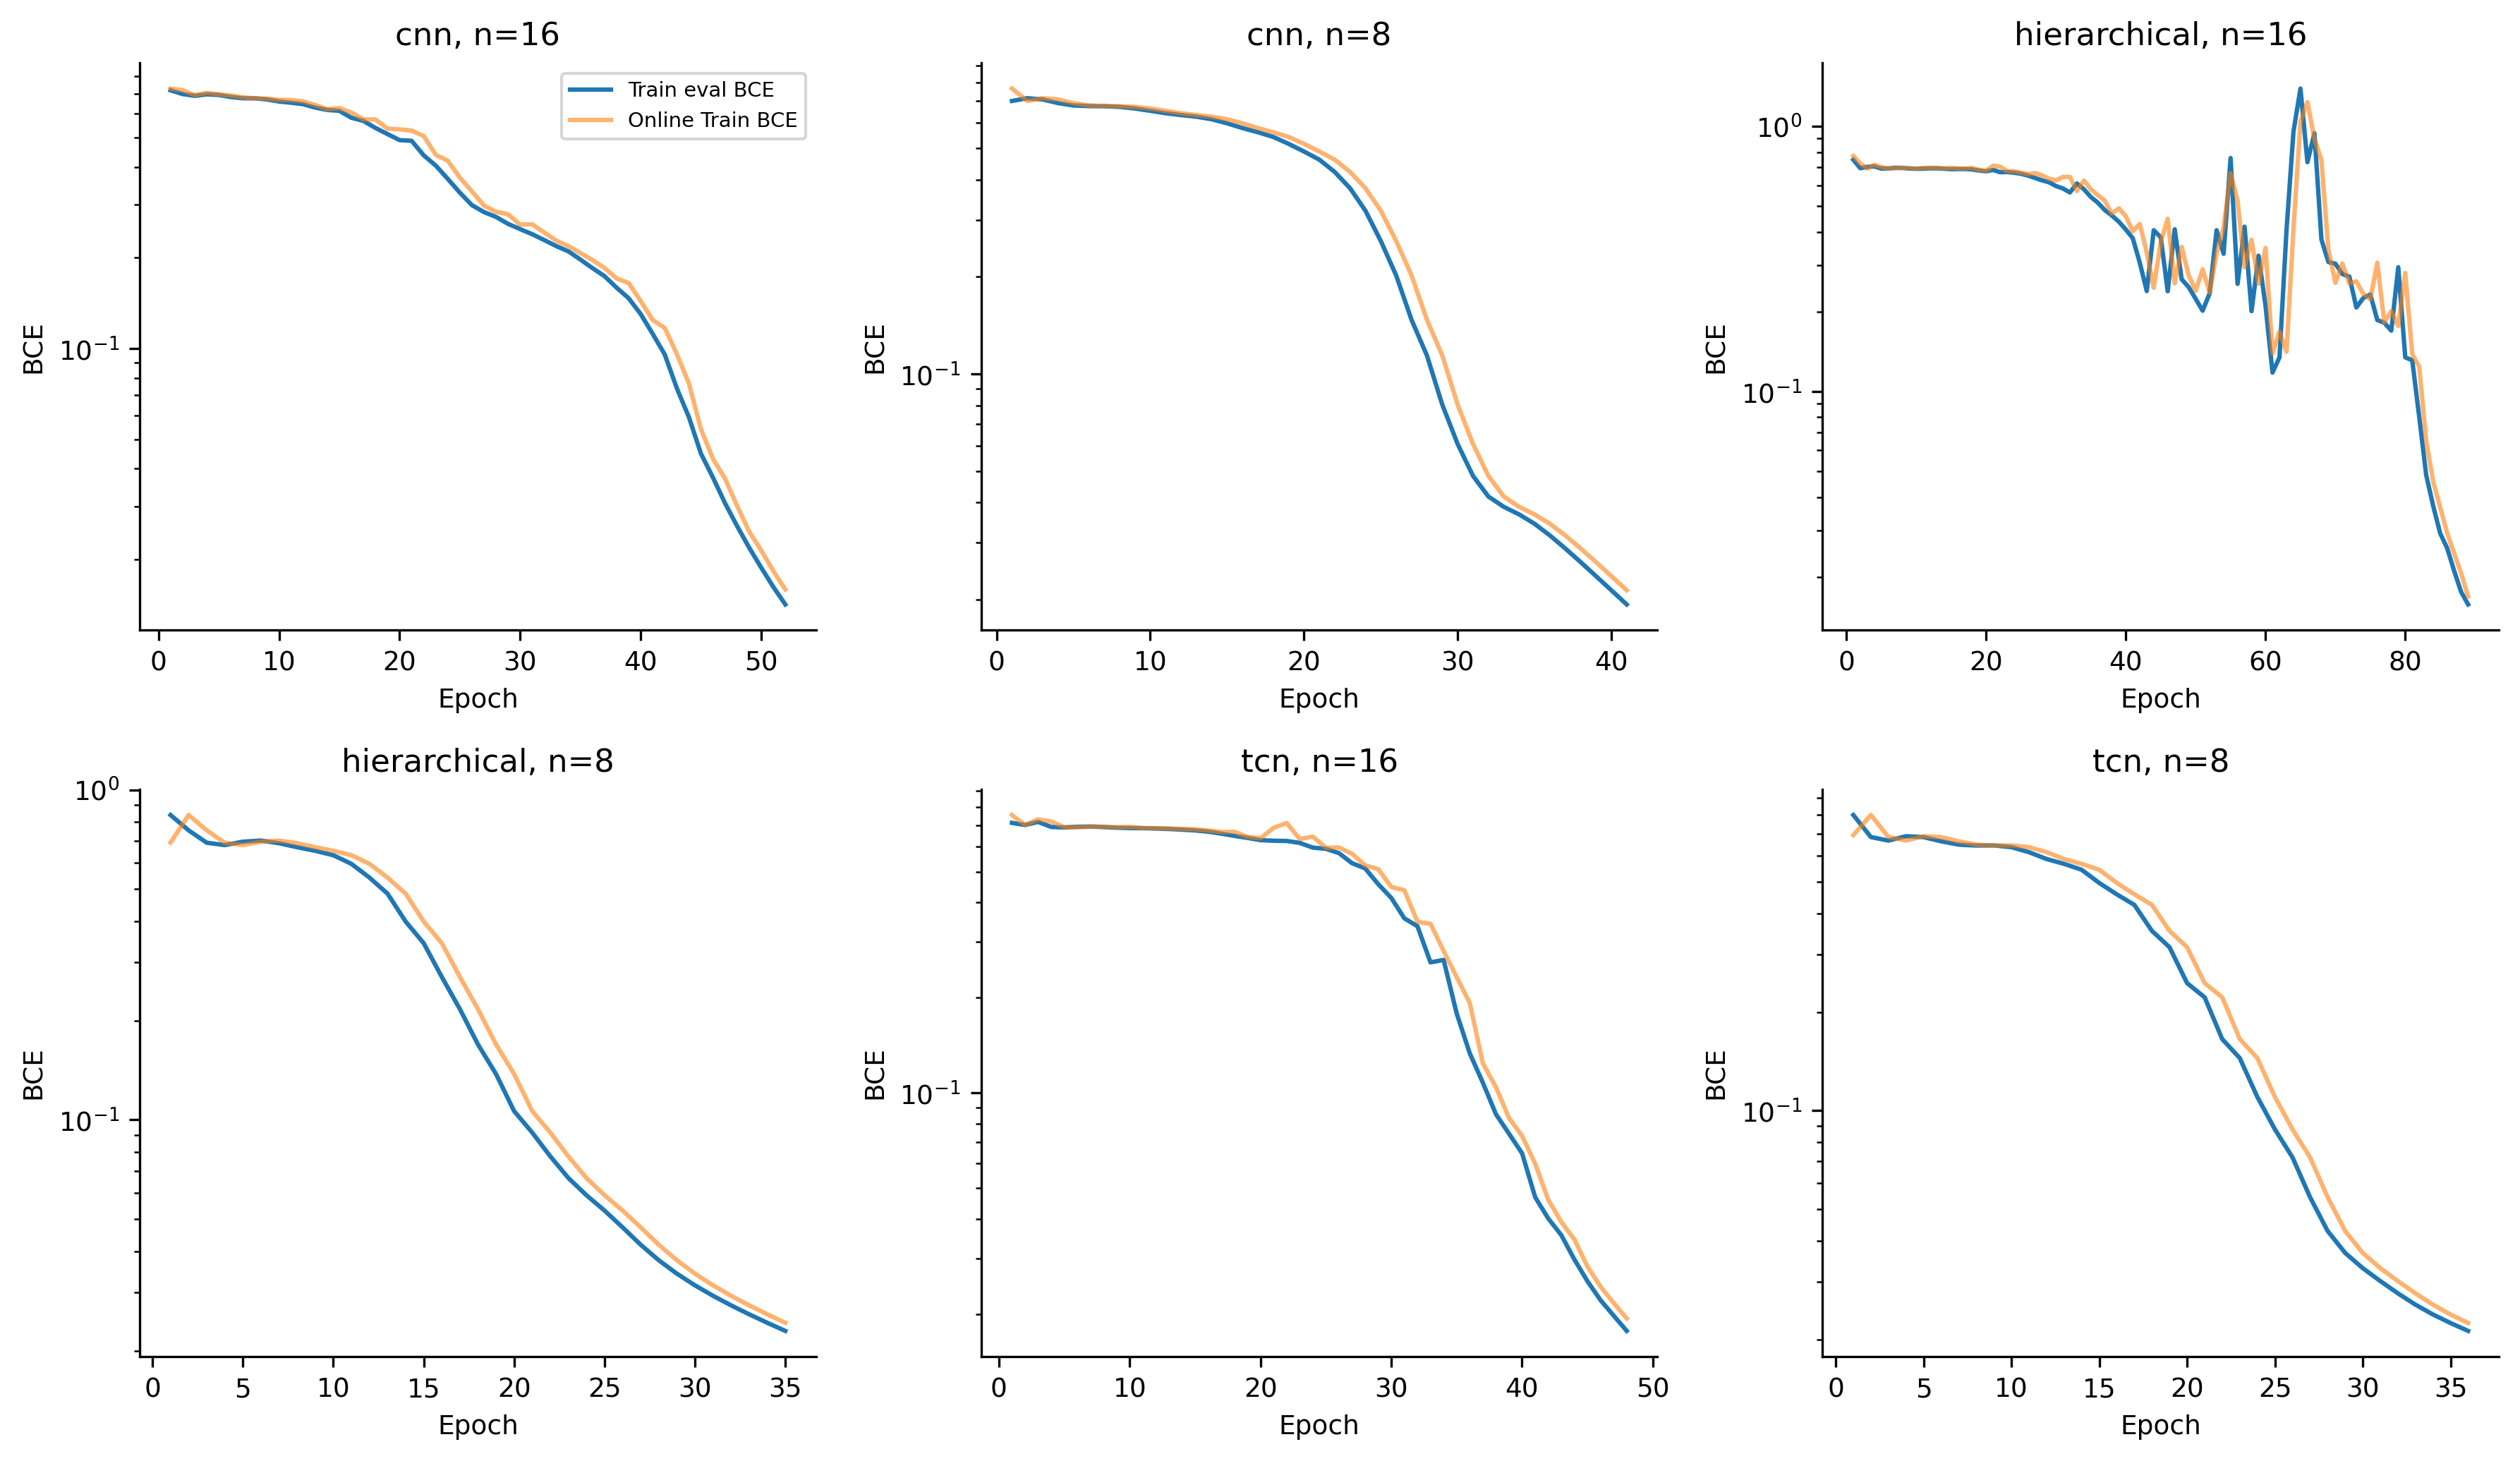

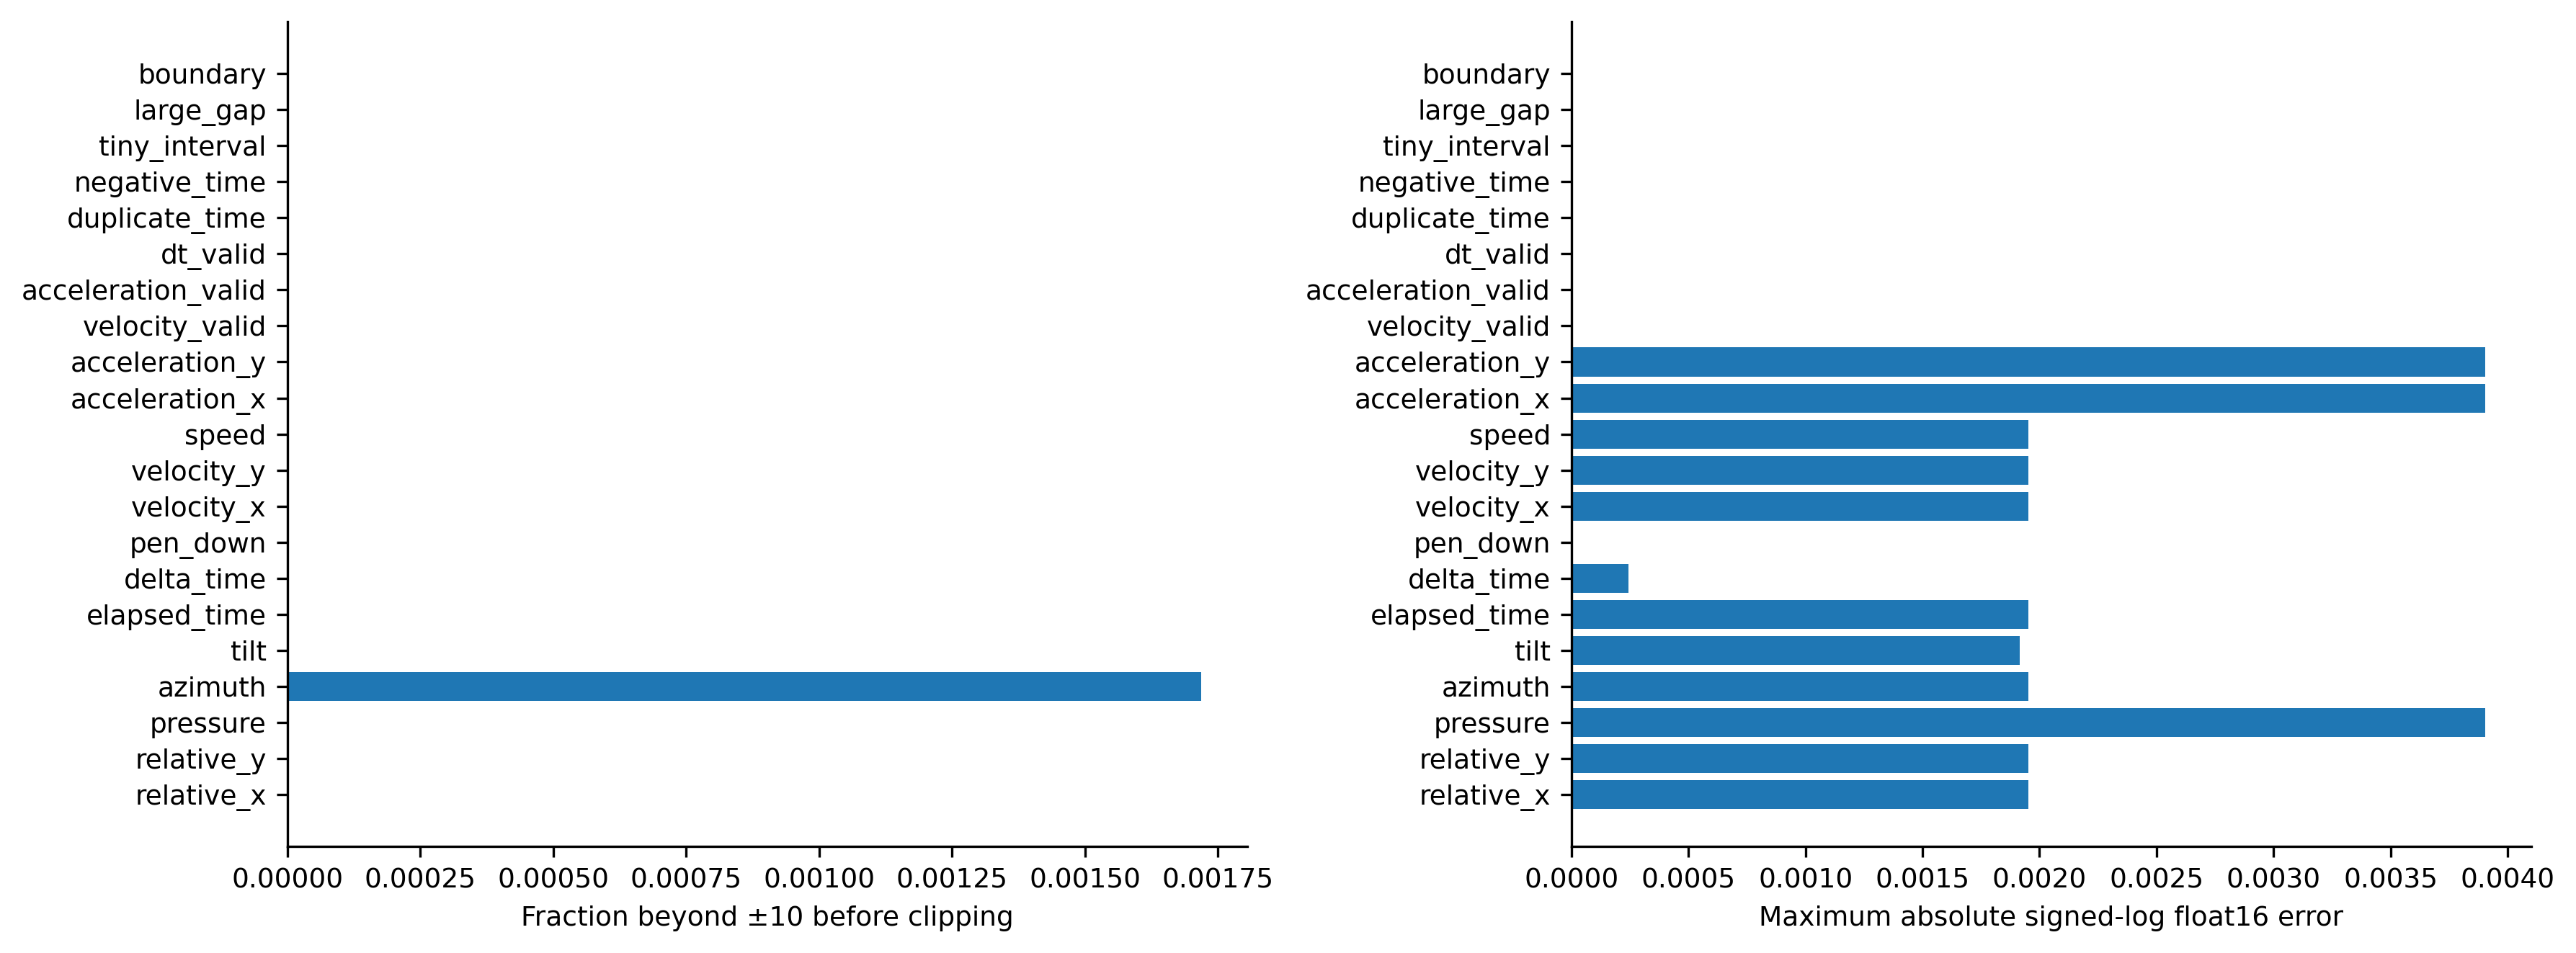

In [3]:
figure('p0_memorization_curves')
figure('p0_clipping_and_quantization')

## Phase 1 — Bảng số cuối mỗi cấu hình đã chạy
Checkpoint chọn bằng development-validation BCE. Bảng này không phải OOF Nested CV. Nếu queue còn chạy, các cấu hình chưa hoàn tất sẽ không xuất hiện.

In [4]:
rows = []
for path in sorted((OUT / 'phase1_bottleneck').glob('p1_*/result.json')):
    result = json.loads(path.read_text(encoding='utf-8'))
    if 'architecture' not in result: continue
    rows.append(dict(configuration=result['experiment_id'], **result['metrics'],
                     train_f1_macro=result['train_metrics']['f1_macro'],
                     best_epoch=result['best_epoch'], epochs=result['epochs_run'],
                     parameters=result['parameters'], seconds=result['training_seconds'],
                     peak_gpu_mib=result['peak_gpu_tensor_mib']))
development = pd.DataFrame(rows)
if len(development): display(development.sort_values('f1_macro', ascending=False).reset_index(drop=True))
else: display(Markdown('Chưa có cấu hình development hoàn tất.'))

,configuration,accuracy,f1_macro,auc,pr_auc,balanced_accuracy,sensitivity,specificity,brier,train_f1_macro,best_epoch,epochs,parameters,seconds,peak_gpu_mib
0,p1_hierarchical_task_to_person_duration,0.819444,0.808784,0.921094,0.881435,0.803125,0.950,0.65625,0.111194,0.861836,16,28,29810,177.836225,379.656738
1,p1_hierarchical_lr003,0.763889,0.746216,0.846875,0.858936,0.743750,0.925,0.56250,0.173214,0.821473,38,50,29810,328.264644,394.623047
2,p1_hierarchical_stroke_to_task_duration,0.736111,0.731922,0.805469,0.804797,0.731250,0.775,0.68750,0.193951,0.935807,36,48,29810,311.043864,392.988281
3,p1_task_lower-loops-fast,0.666667,0.660110,0.663281,0.730859,0.659375,0.725,0.59375,0.231244,0.643682,12,24,4178,89.849550,314.879395
4,p1_hierarchical_task_to_person_mean,0.652778,0.641077,0.708594,0.734124,0.640625,0.750,0.53125,0.218083,0.820937,30,42,29810,264.837012,394.286133
5,p1_hierarchical_window_to_stroke_mean,0.638889,0.634375,0.714063,0.763903,0.634375,0.675,0.59375,0.222899,0.767594,23,35,29810,227.914875,392.735352
6,p1_cnn_lr003,0.638889,0.601702,0.758594,0.752527,0.612500,0.850,0.37500,0.212197,0.747444,19,31,4178,107.034970,314.205078
7,p1_hierarchical_window_to_stroke_duration,0.638889,0.593750,0.668750,0.699570,0.609375,0.875,0.34375,0.230177,0.667855,23,35,29810,225.192405,393.241211
8,p1_hierarchical_window_to_stroke_mean_max,0.583333,0.509091,0.685938,0.714193,0.546875,0.875,0.21875,0.231559,0.679987,23,35,31890,232.589682,393.299316
9,p1_hierarchical_mil,0.583333,0.509091,0.617188,0.658230,0.546875,0.875,0.21875,0.233569,0.698752,21,33,29810,231.311351,377.392578


## Phase 1 — Probe vật lý
Ridge/RBF-Ridge dùng inner participant CV, scaler X/Y fit Train. Target thuộc đúng scope observation. Window/segment không có chuyển động hợp lệ bị loại complete-case, có bảng coverage. Feature map544 chiều, pooled32 chiều; multi4 probe128 chiều. Padding để lại dấu vết chiều dài; pen-up là input flag trực tiếp. Không diễn giải các probe như bằng chứng lâm sàng.

In [5]:
probes = table('tables/phase1_layer_probes.csv')
if probes is not None:
    display(probes[probes.method == 'ridge'].pivot(index='level', columns='target', values='r2').round(4))
coverage = table('tables/phase1_probe_coverage.csv')

,level,method,target,alpha,r2,mae,correlation,dimensions,fit_participants,validation_participants,observation_scope
0,cnn_feature_map,ridge,log_speed_mean,10.0,0.720181,0.360435,0.850015,544,143,72,Within-observation target; participant-balance...
1,cnn_feature_map,ridge,log_speed_std,10.0,0.512630,0.402736,0.723359,544,143,72,Within-observation target; participant-balance...
2,cnn_feature_map,ridge,log_pressure_std,10.0,0.406939,0.623367,0.642901,544,143,72,Within-observation target; participant-balance...
3,cnn_feature_map,ridge,log_duration,10.0,0.997732,0.005497,0.998866,544,143,72,Within-observation target; participant-balance...
4,cnn_feature_map,ridge,log_path_length,10.0,0.884267,0.270240,0.940737,544,143,72,Within-observation target; participant-balance...
...,...,...,...,...,...,...,...,...,...,...,...
187,hierarchical_reference_window,rbf_ridge,log_duration,0.1,0.714561,0.060711,0.845779,42,143,72,Within-observation target; participant-balance...
188,hierarchical_reference_window,rbf_ridge,log_path_length,0.1,0.763576,0.339770,0.874207,42,143,72,Within-observation target; participant-balance...
189,hierarchical_reference_window,rbf_ridge,log_width,0.1,0.679146,0.377523,0.824486,42,143,72,Within-observation target; participant-balance...
190,hierarchical_reference_window,rbf_ridge,pen_up_fraction,0.1,1.000000,0.000000,0.000000,42,143,72,Within-observation target; participant-balance...


target,log_duration,log_path_length,log_pressure_std,log_speed_mean,log_speed_std,log_width,peak_speed_position,pen_up_fraction
level,,,,,,,,
cnn_feature_map,0.9977,0.8843,0.4069,0.7202,0.5126,0.7226,0.1312,1.0000
cnn_reference_window,0.5632,0.8703,0.5810,0.9857,0.8736,0.7997,0.0560,1.0000
cnn_window,0.7204,0.7633,0.1743,0.6811,0.4518,0.6312,0.0203,1.0000
hierarchical_feature_map,0.9971,0.8541,0.3692,0.6657,0.4885,0.7047,0.0680,1.0000
hierarchical_participant,0.9539,0.1704,0.2921,0.6329,0.4797,0.0450,-0.1283,0.4634
hierarchical_reference_person,0.9862,0.9294,0.8061,0.9871,0.9276,0.7863,-0.1129,0.9974
hierarchical_reference_segment,0.8441,0.9527,0.7294,0.9841,0.8814,0.8552,0.0395,1.0000
hierarchical_reference_task,0.9988,0.9713,0.9357,0.9901,0.9171,0.8439,0.0733,1.0000
hierarchical_reference_window,0.5632,0.8703,0.5810,0.9857,0.8736,0.7997,0.0560,1.0000


,level,rows,defined_rows,excluded_undefined_motion_rows,participants
0,cnn_feature_map,13760,8654,5106,215
1,cnn_window,13760,8654,5106,215
2,cnn_reference_window,13760,8654,5106,215
3,hierarchical_feature_map,13760,8654,5106,215
4,hierarchical_window,13760,8654,5106,215
5,hierarchical_segment,13760,6621,7139,215
6,hierarchical_task,3010,3010,0,215
7,hierarchical_participant,215,215,0,215
8,hierarchical_reference_person,215,215,0,215
9,hierarchical_reference_segment,13760,6621,7139,215


In [6]:
retention = table('tables/phase1_pooling_physical_probes.csv')
if retention is not None:
    display(retention[retention.method == 'ridge'].pivot(index='pool', columns='target', values='r2').round(4))

,pool,method,target,dimensions,alpha,r2,mae
0,mean,ridge,log_speed_mean,32,0.1,0.675276,0.368346
1,mean,ridge,log_speed_std,32,0.1,0.439244,0.429246
2,mean,ridge,log_pressure_std,32,0.1,0.159602,0.790207
3,mean,ridge,log_duration,32,0.1,0.696492,0.067167
4,mean,ridge,log_path_length,32,0.1,0.758032,0.384172
5,mean,ridge,log_width,32,0.1,0.620023,0.424545
6,mean,ridge,pen_up_fraction,32,0.1,1.000000,0.000000
7,mean,ridge,peak_speed_position,32,0.1,0.016390,0.293929
8,mean,rbf_ridge,log_speed_mean,32,0.1,0.628584,0.394735
9,mean,rbf_ridge,log_speed_std,32,0.1,0.444686,0.422319


target,log_duration,log_path_length,log_pressure_std,log_speed_mean,log_speed_std,log_width,peak_speed_position,pen_up_fraction
pool,,,,,,,,
attention,0.6934,0.7579,0.1599,0.6727,0.4361,0.6173,0.0166,1.0
mean,0.6965,0.7580,0.1596,0.6753,0.4392,0.6200,0.0164,1.0
mean_max,0.6869,0.7957,0.1510,0.6284,0.4582,0.6070,0.0075,1.0
mean_max_std,0.6767,0.7873,0.1558,0.6229,0.4630,0.6007,0.0069,1.0
multi4,0.9848,0.8307,0.3224,0.6433,0.4444,0.6496,0.1281,1.0


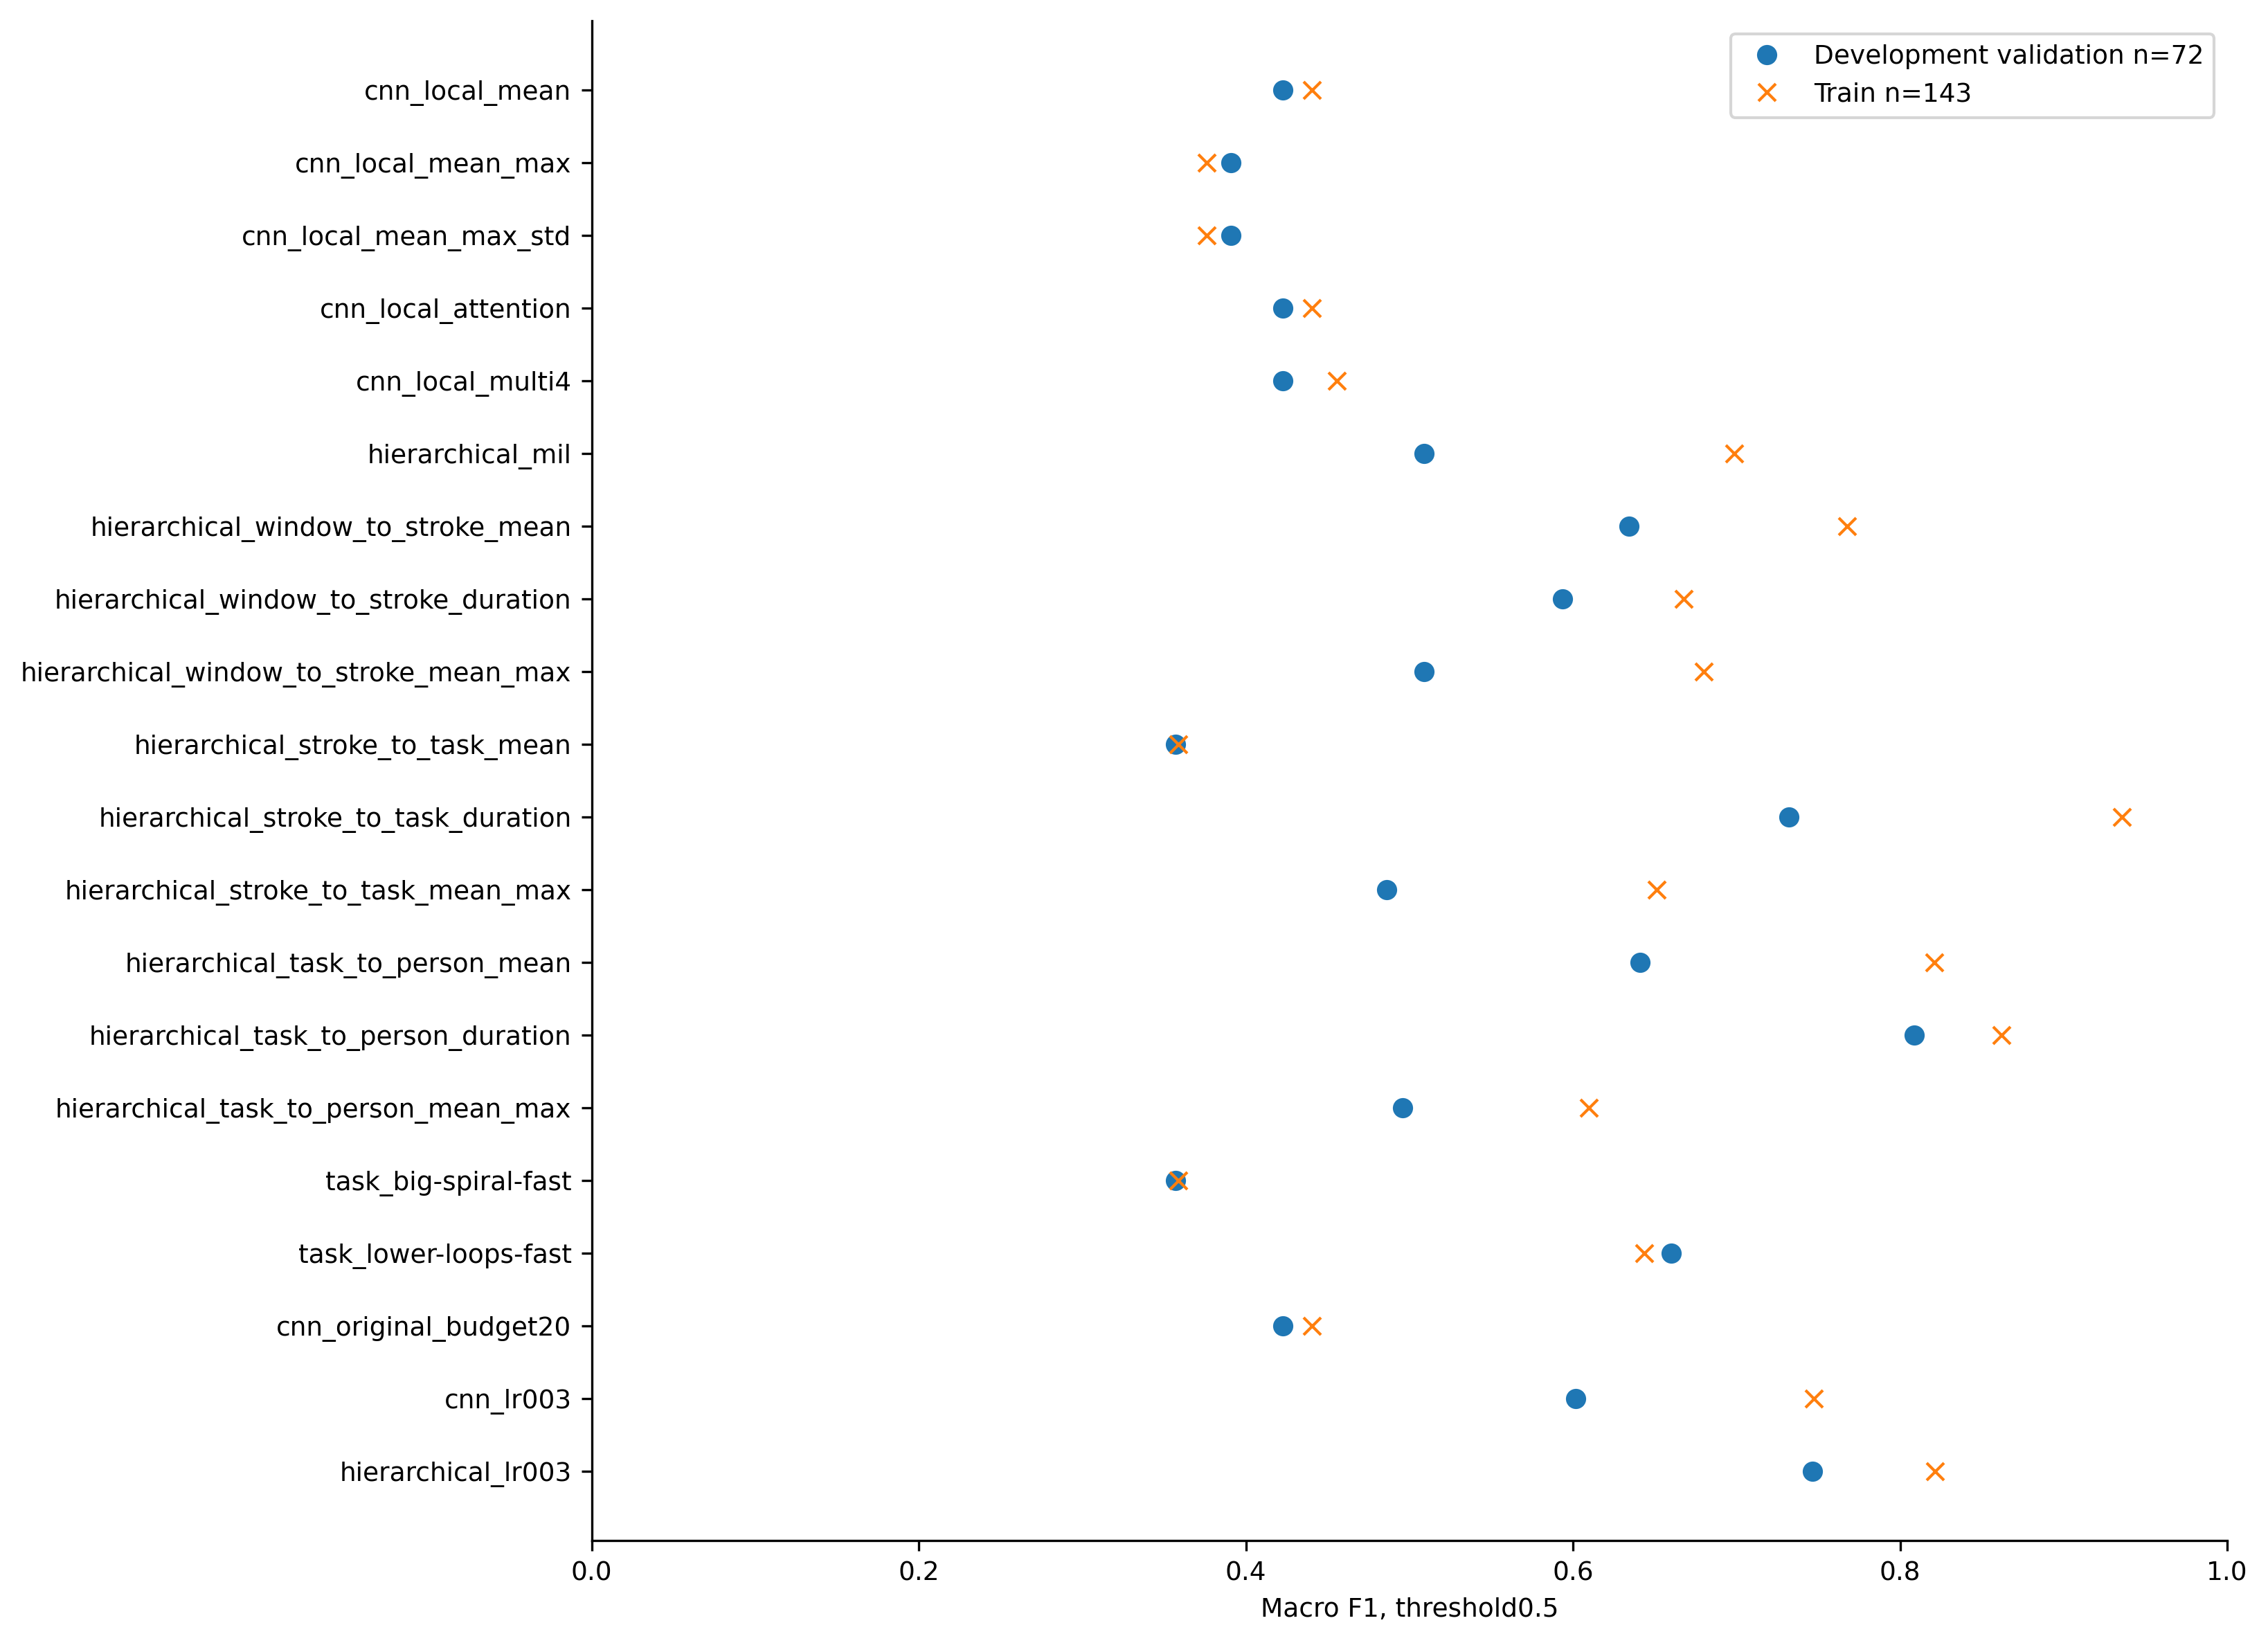

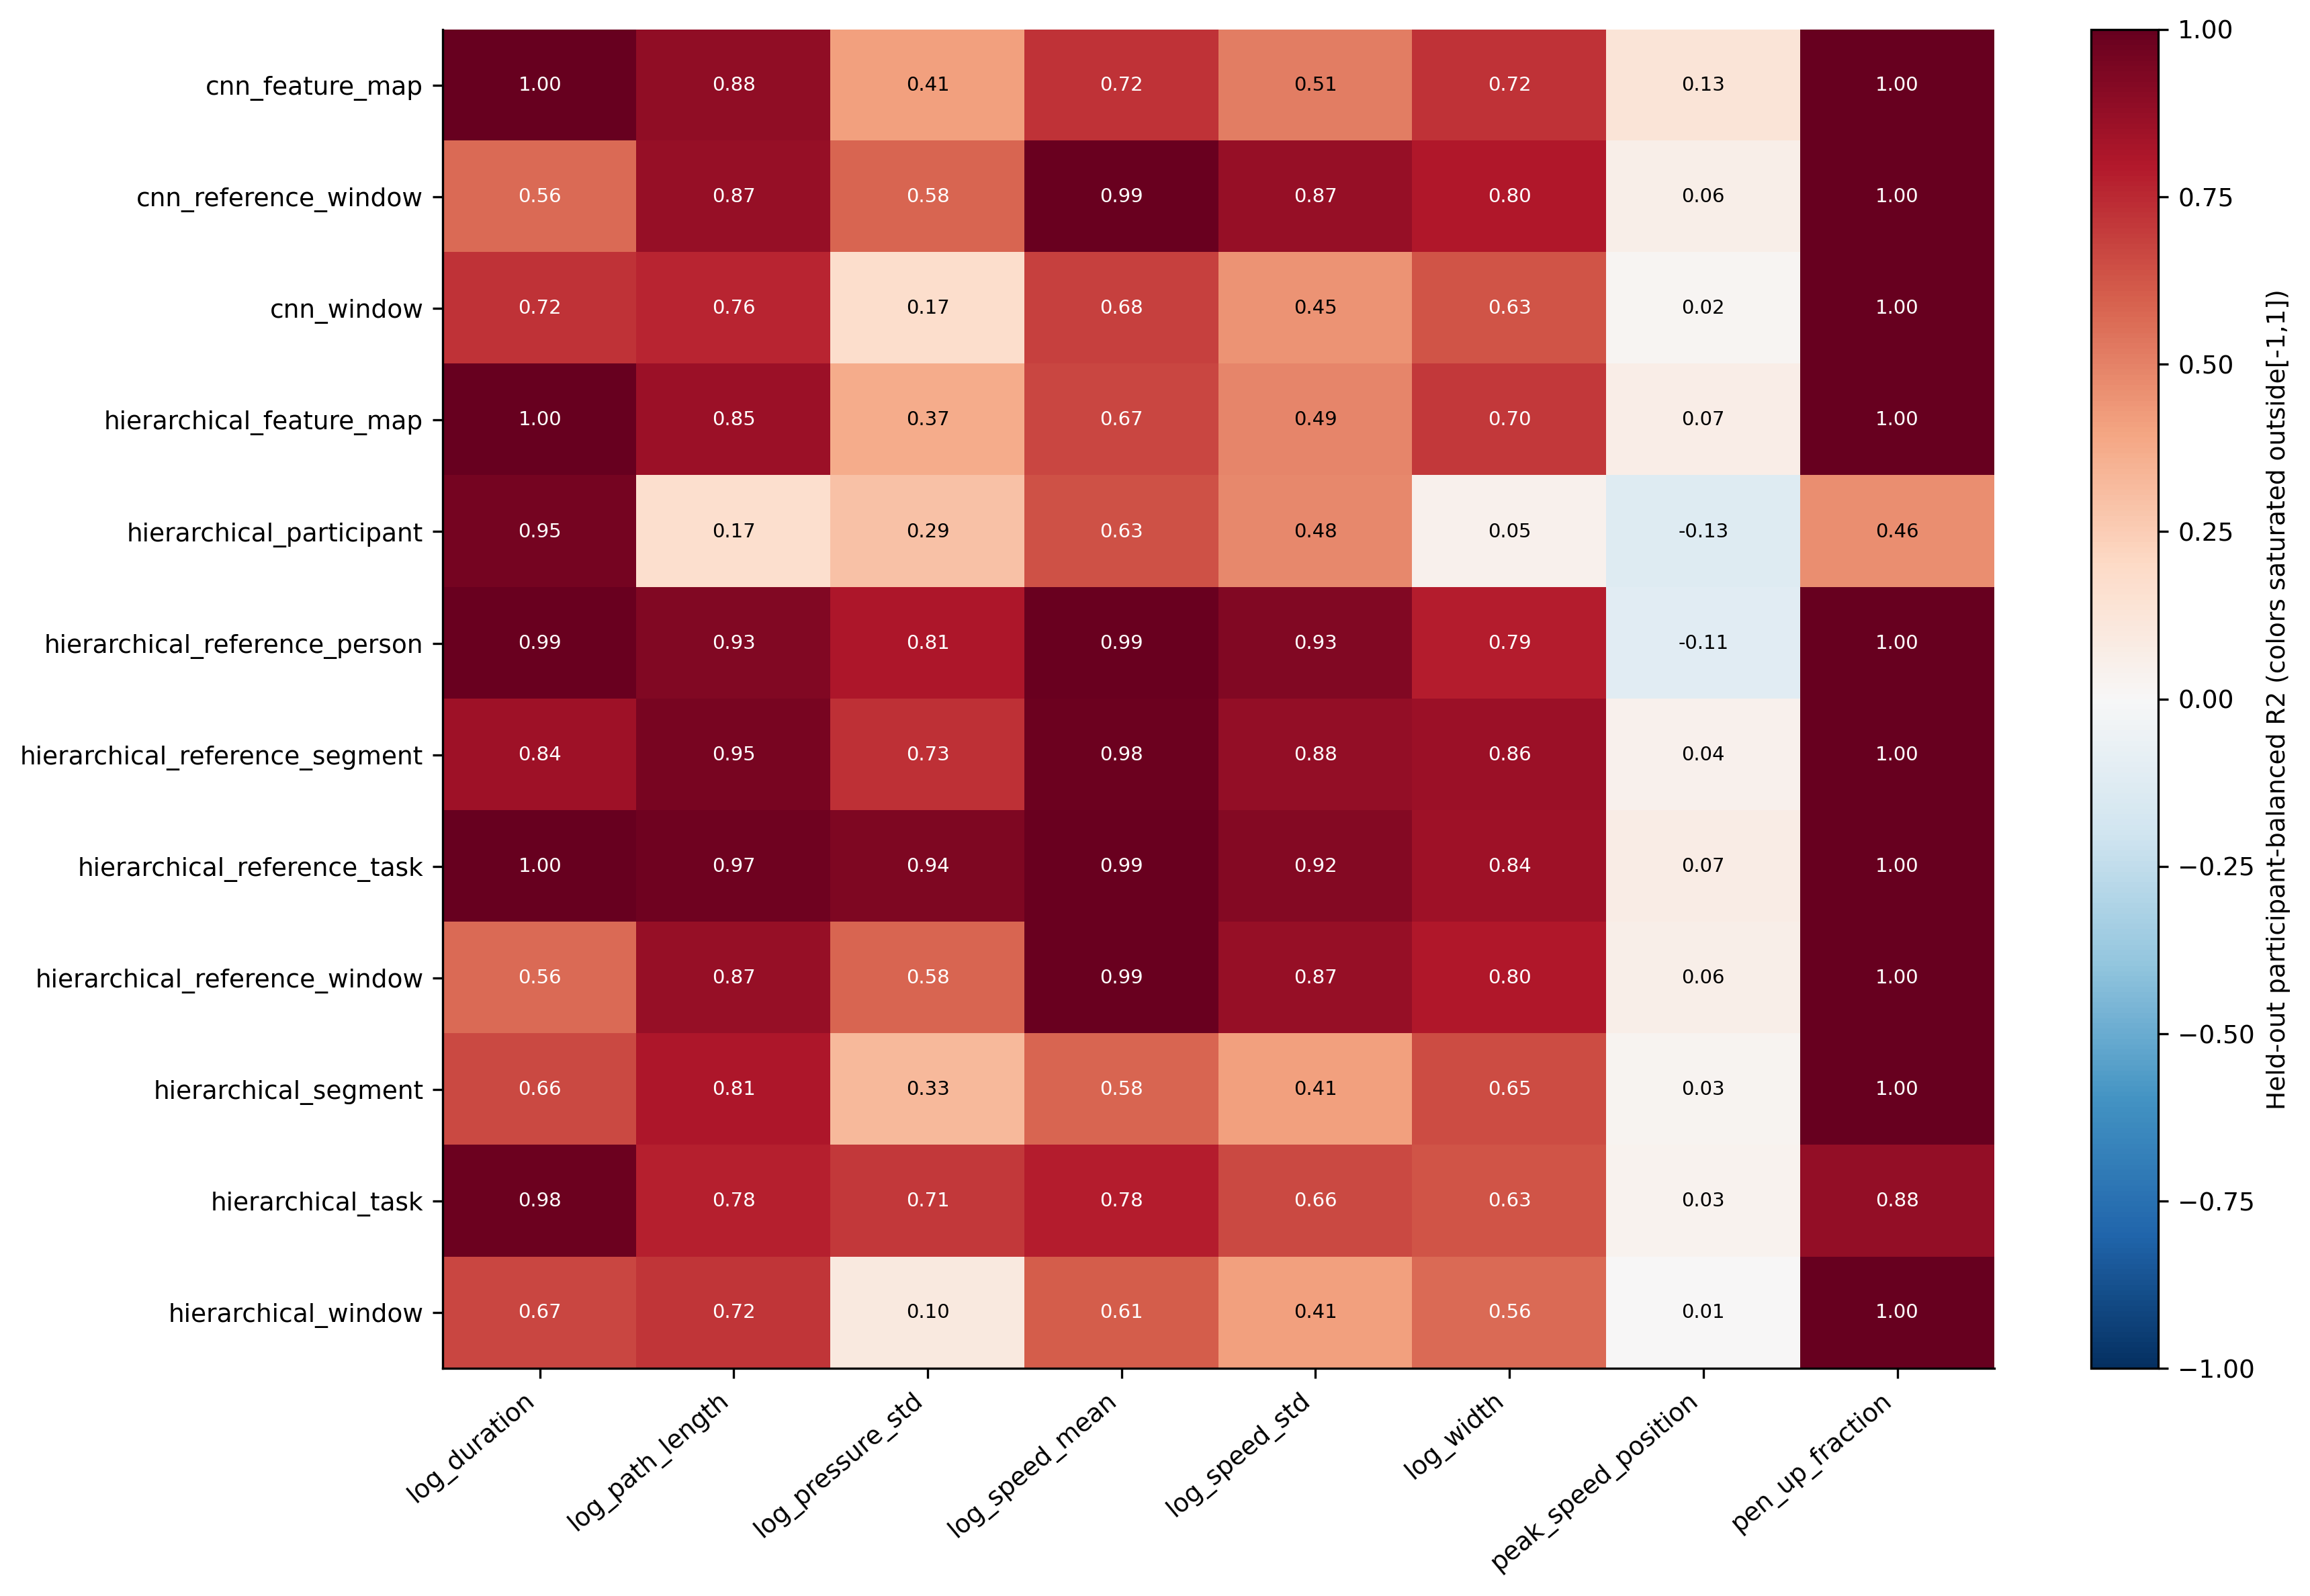

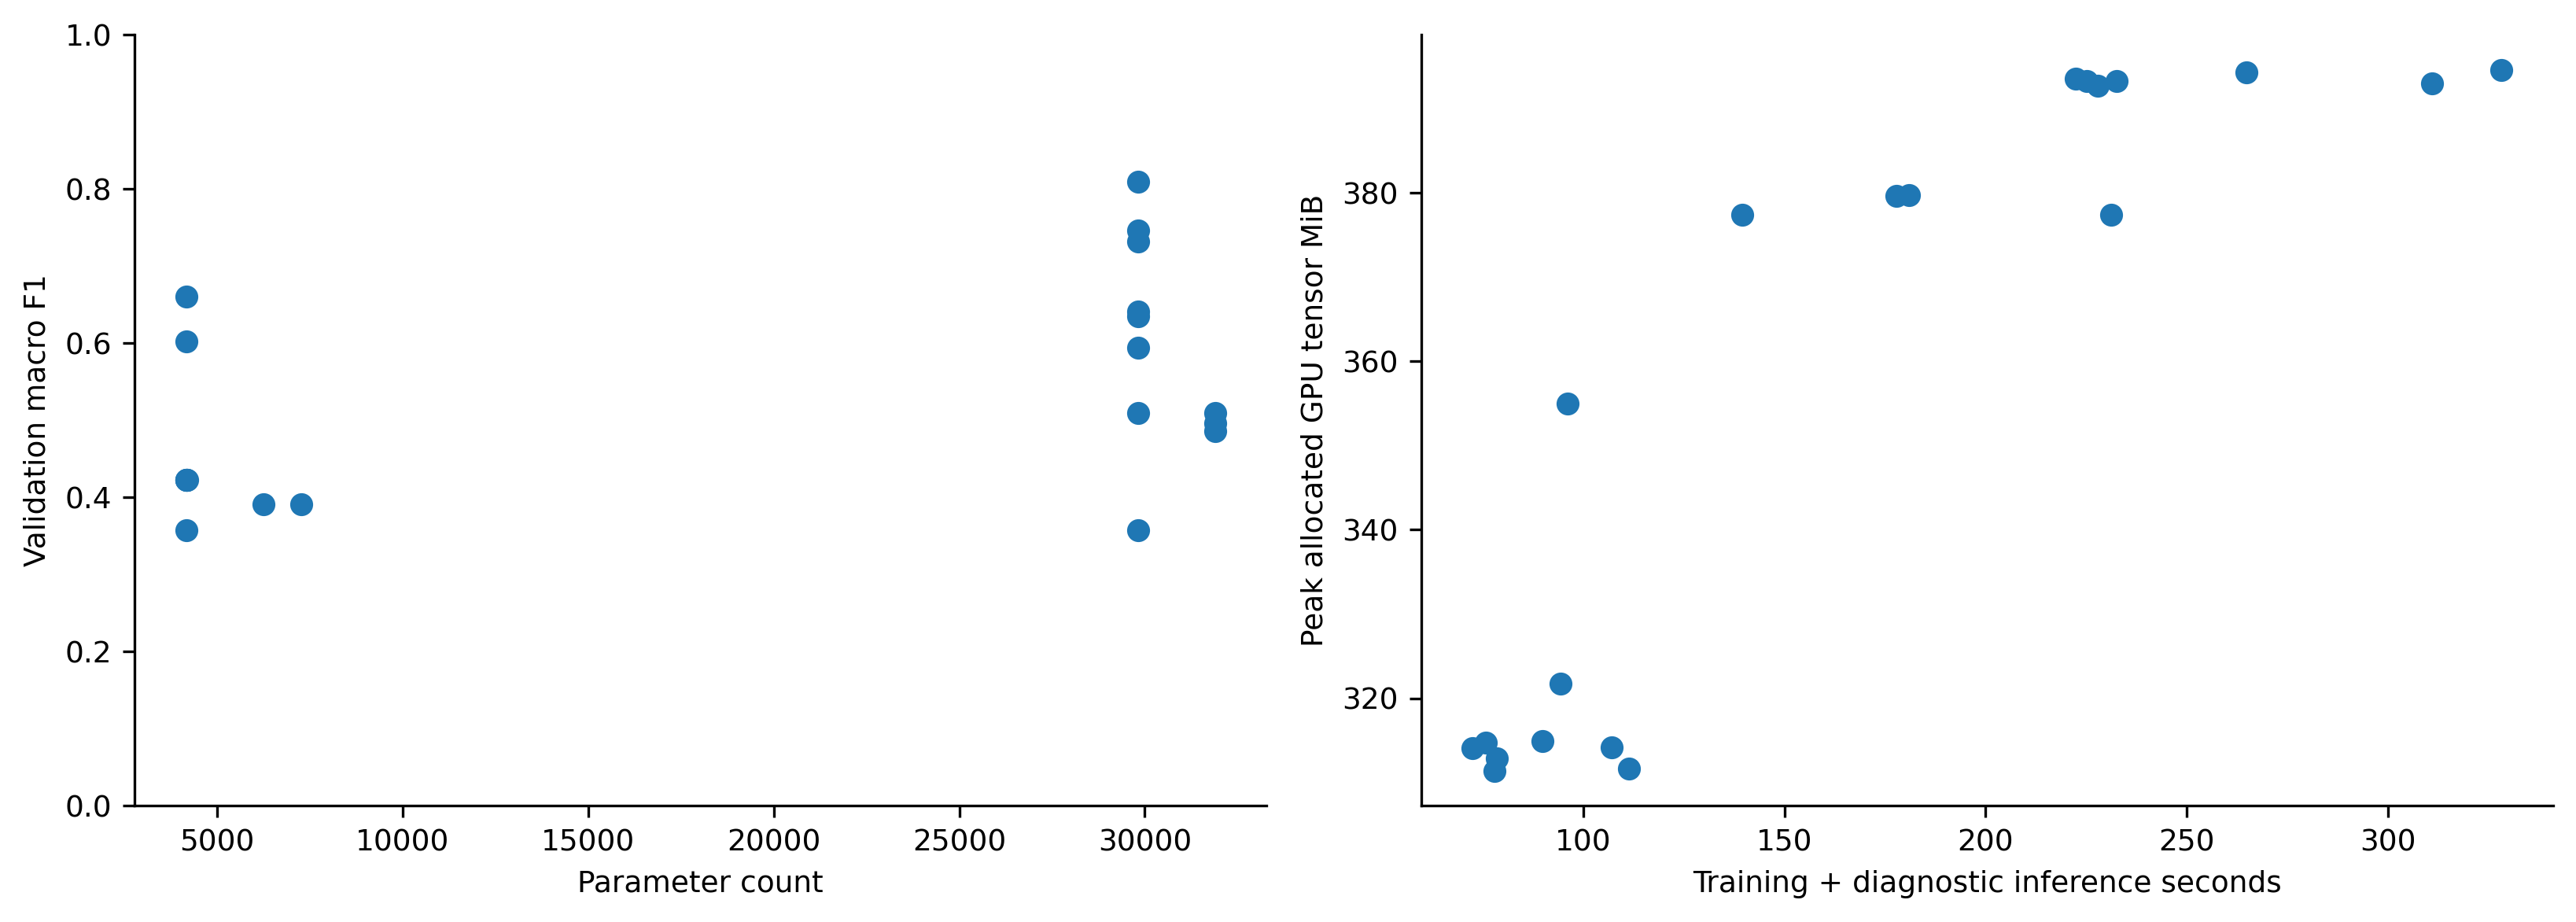

In [7]:
figure('p1_controlled_comparison')
figure('p1_layer_information')
figure('p1_resource_cost')

## Phase 2 — Statistical, MIL và Stroke Transformer
Chỉ đọc kết quả khi có artifact. Không giữ Transformer chỉ vì kiến trúc mới.

In [8]:
phase2 = table('tables/phase2_development_comparison.csv')

,configuration,seed,accuracy,f1_macro,auc,pr_auc,balanced_accuracy,sensitivity,specificity,brier,train_f1_macro,parameters,best_epoch,epochs,seconds,peak_gpu_mib
0,statistical,42,0.569444,0.559155,0.617969,0.620142,0.559375,0.65,0.46875,0.236928,0.776934,19730,12,24,919.096932,294.121582


## Phase 3 — Masked motor SSL
Pretraining chỉ được dùng participant Train của từng split. Không coi reconstruction tốt là cải thiện downstream khi chưa có đối chứng.

In [9]:
phase3 = table('tables/phase3_ssl_comparison.csv')

**Chưa có artifact:** `tables/phase3_ssl_comparison.csv`

## Phase 4 — Nested CV và complementarity
Bảng development phía trên không thay thế bảng OOF. Fusion phải dùng cross-fitted Train inputs, không dùng outer Test labels để chọn trọng số.

In [10]:
nested = table('tables/phase4_nested_comparison.csv')
complementarity = table('tables/phase4_complementarity.csv')

**Chưa có artifact:** `tables/phase4_nested_comparison.csv`

**Chưa có artifact:** `tables/phase4_complementarity.csv`

## Báo cáo và trạng thái xác minh
Mở báo cáo đã tồn tại. Thiếu báo cáo nghĩa là chưa hoàn thành, không phải kết quả âm tính.

In [11]:
for name in ['PHASE0_REPORT_VI.md', 'PHASE1_REPORT_VI.md', 'PHASE2_REPORT_VI.md',
             'PHASE3_REPORT_VI.md', 'PHASE4_REPORT_VI.md', 'REPORT_VI.md', 'FINAL_DECISION_VI.md']:
    path = OUT / name
    display(Markdown(('Đã có: ' if path.exists() else 'Chưa hoàn thành: ') + '`' + name + '`'))
ledger = pd.read_csv(OUT / 'EXPERIMENT_LEDGER.csv')
display(ledger.groupby(['phase', 'training_status'], dropna=False).size().rename('experiments').reset_index())

Đã có: `PHASE0_REPORT_VI.md`

Đã có: `PHASE1_REPORT_VI.md`

Chưa hoàn thành: `PHASE2_REPORT_VI.md`

Chưa hoàn thành: `PHASE3_REPORT_VI.md`

Chưa hoàn thành: `PHASE4_REPORT_VI.md`

Chưa hoàn thành: `REPORT_VI.md`

Chưa hoàn thành: `FINAL_DECISION_VI.md`

,phase,training_status,experiments
0,0,completed,32
1,1,completed,40
2,1,cpu_completed,38
3,1,planned,4
4,2,completed,1
5,2,planned,1
6,2,running,1
7,3,planned,1
8,4,planned,3
